# **01. Olist Dataset Loading and Initial Exploration**

In [19]:
import pandas as pd
from pathlib import Path
import seaborn as sns
import matplotlib.pyplot as plt

In [6]:
data_dir = Path("../data")
orders = pd.read_csv(data_dir / "olist_orders_dataset.csv")

### **1.1 Convertir tipos de datos de las columnas del dataset**

In [15]:
print(orders.shape)
print(orders.info())

(99441, 8)
<class 'pandas.DataFrame'>
RangeIndex: 99441 entries, 0 to 99440
Data columns (total 8 columns):
 #   Column                         Non-Null Count  Dtype         
---  ------                         --------------  -----         
 0   order_id                       99441 non-null  str           
 1   customer_id                    99441 non-null  str           
 2   order_status                   99441 non-null  str           
 3   order_purchase_timestamp       99441 non-null  datetime64[us]
 4   order_approved_at              99281 non-null  datetime64[us]
 5   order_delivered_carrier_date   97658 non-null  datetime64[us]
 6   order_delivered_customer_date  96476 non-null  datetime64[us]
 7   order_estimated_delivery_date  99441 non-null  datetime64[us]
dtypes: datetime64[us](5), str(3)
memory usage: 6.1 MB
None


In [12]:
columnas_fecha = [
    "order_purchase_timestamp",
    "order_approved_at",
    "order_delivered_carrier_date",
    "order_delivered_customer_date",
    "order_estimated_delivery_date"
]

orders[columnas_fecha] = orders[columnas_fecha].apply(pd.to_datetime, errors="coerce")

### **1.2 Conteo de valores nulos en cada una de las columnas**

In [7]:
orders["order_status"].value_counts()

order_status
delivered      96478
shipped         1107
canceled         625
unavailable      609
invoiced         314
processing       301
created            5
approved           2
Name: count, dtype: int64

In [16]:
orders.isna().sum()

order_id                            0
customer_id                         0
order_status                        0
order_purchase_timestamp            0
order_approved_at                 160
order_delivered_carrier_date     1783
order_delivered_customer_date    2965
order_estimated_delivery_date       0
dtype: int64

In [17]:
orders.dtypes

order_id                                    str
customer_id                                 str
order_status                                str
order_purchase_timestamp         datetime64[us]
order_approved_at                datetime64[us]
order_delivered_carrier_date     datetime64[us]
order_delivered_customer_date    datetime64[us]
order_estimated_delivery_date    datetime64[us]
dtype: object

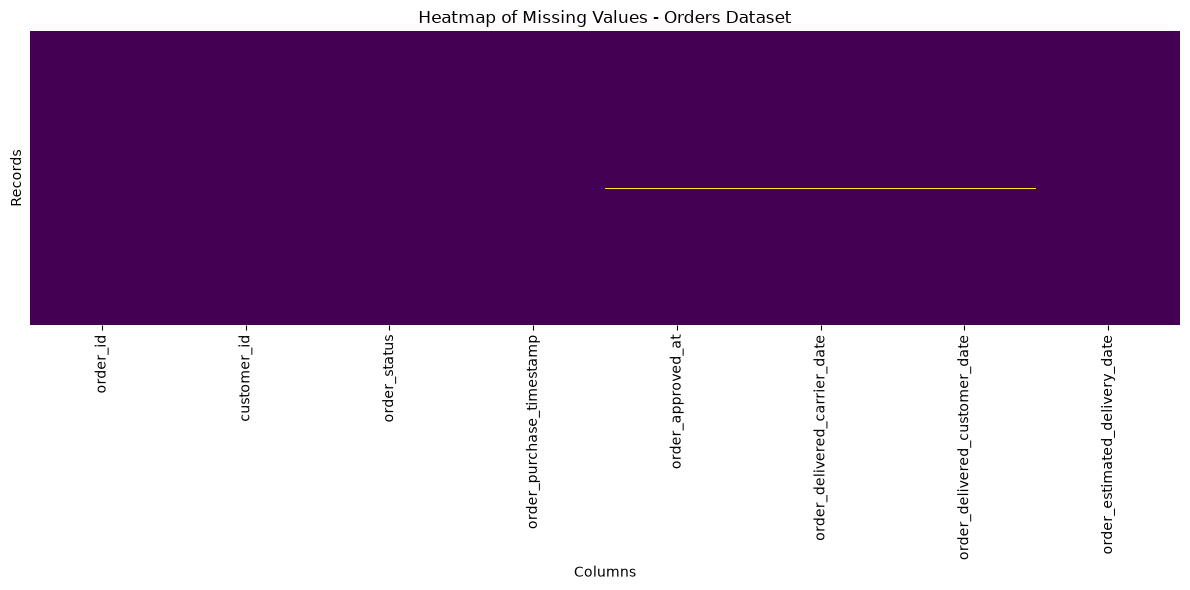

In [ ]:
plt.figure(figsize=(12, 6))

sns.heatmap(
    orders.isna(),
    cbar=False,
    yticklabels=False,
    cmap="viridis"
)

plt.title("Heatmap de Valores Nulos - Orders Dataset")
plt.xlabel("Columns")
plt.ylabel("Records")

plt.tight_layout()
plt.show()

### **1.3 Valores Únicos del conjunto de datos**

In [26]:
print(f"order_id: {orders["order_id"].nunique()}")
print(f"customer_id: {orders["customer_id"].nunique()}")
print(f"order_status: {orders["order_status"].nunique()}")
orders["order_status"].unique()

order_id: 99441
customer_id: 99441
order_status: 8


<StringArray>
[  'delivered',    'invoiced',     'shipped',  'processing', 'unavailable',
    'canceled',     'created',    'approved']
Length: 8, dtype: str

In [28]:
orders.groupby("order_status")[
    [
        "order_approved_at",
        "order_delivered_carrier_date",
        "order_delivered_customer_date"
    ]
].agg(lambda col: col.isna().sum())

,order_approved_at,order_delivered_carrier_date,order_delivered_customer_date
order_status,,,
approved,0,2,2
canceled,141,550,619
created,5,5,5
delivered,14,2,8
invoiced,0,314,314
processing,0,301,301
shipped,0,0,1107
unavailable,0,609,609


### **1.3 Calidad e integridad de los registros**

In [35]:
orders[orders.duplicated()]
orders[orders.duplicated(keep=False)]

,order_id,customer_id,order_status,order_purchase_timestamp,order_approved_at,order_delivered_carrier_date,order_delivered_customer_date,order_estimated_delivery_date


In [32]:
orders["order_id"].is_unique # No hay identificadores de perdido repetidos
orders["order_purchase_timestamp"].agg(["min", "max"])
orders["order_status"].value_counts(normalize=True).mul(100).round(2)

order_status
delivered      97.02
shipped         1.11
canceled        0.63
unavailable     0.61
invoiced        0.32
processing      0.30
created         0.01
approved        0.00
Name: proportion, dtype: float64

In [36]:
orders.groupby(
    orders["order_purchase_timestamp"].dt.to_period("M")
).size()

order_purchase_timestamp
2016-09       4
2016-10     324
2016-12       1
2017-01     800
2017-02    1780
2017-03    2682
2017-04    2404
2017-05    3700
2017-06    3245
2017-07    4026
2017-08    4331
2017-09    4285
2017-10    4631
2017-11    7544
2017-12    5673
2018-01    7269
2018-02    6728
2018-03    7211
2018-04    6939
2018-05    6873
2018-06    6167
2018-07    6292
2018-08    6512
2018-09      16
2018-10       4
Freq: M, dtype: int64

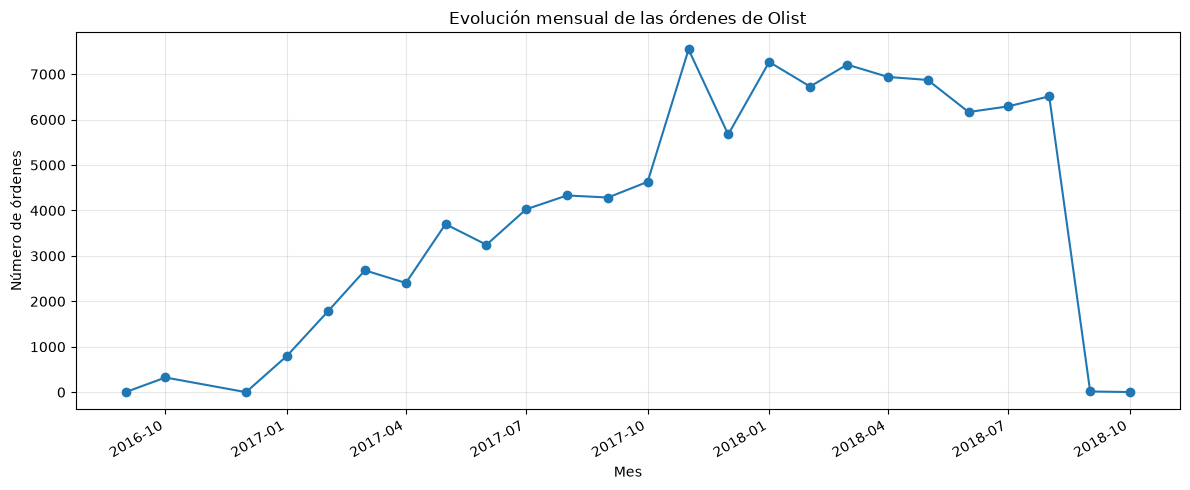

In [37]:
ordenes_mensuales = orders.groupby(
    orders["order_purchase_timestamp"].dt.to_period("M")
).size()

ordenes_mensuales.index = ordenes_mensuales.index.to_timestamp()

ordenes_mensuales.plot(
    kind="line",
    figsize=(12, 5),
    marker="o",
    title="Evolución mensual de las órdenes de Olist"
)

plt.xlabel("Mes")
plt.ylabel("Número de órdenes")
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()